# ResNet-18 Training

Runs the reproducible ResNet-18 baseline on the fixed training and validation split. The script performs its required sanity check before full training and does not load the test split.

In [2]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd().parent
assert (project_root / 'src' / 'train_resnet.py').exists(), 'Run this notebook from notebooks/'

## Train

The script uses ImageNet `ResNet18_Weights.IMAGENET1K_V1`, CrossEntropyLoss, AdamW (`lr=0.0001`, `weight_decay=0.0001`), batch size 32, a maximum of 20 epochs, and seed 42.

In [3]:
%run ../src/train_resnet.py

Sanity check passed. Training on cuda for up to 20 epochs.
Epoch 01/20 | train loss 4.3295, acc 0.0587 | val loss 3.7834, acc 0.1300
Epoch 02/20 | train loss 3.4240, acc 0.2238 | val loss 3.1138, acc 0.2640
Epoch 03/20 | train loss 2.8349, acc 0.3475 | val loss 2.7186, acc 0.3400
Epoch 04/20 | train loss 2.3671, acc 0.4632 | val loss 2.3135, acc 0.4320
Epoch 05/20 | train loss 2.0046, acc 0.5413 | val loss 1.9994, acc 0.5340
Epoch 06/20 | train loss 1.6530, acc 0.6445 | val loss 1.8445, acc 0.5320
Epoch 07/20 | train loss 1.3683, acc 0.7067 | val loss 1.6618, acc 0.5620
Epoch 08/20 | train loss 1.1451, acc 0.7672 | val loss 1.5332, acc 0.6100
Epoch 09/20 | train loss 0.9156, acc 0.8327 | val loss 1.4995, acc 0.6320
Epoch 10/20 | train loss 0.7784, acc 0.8540 | val loss 1.4437, acc 0.6420
Epoch 11/20 | train loss 0.6287, acc 0.8952 | val loss 1.3650, acc 0.6560
Epoch 12/20 | train loss 0.5294, acc 0.9173 | val loss 1.3934, acc 0.6080
Epoch 13/20 | train loss 0.4084, acc 0.9455 | val los

## Results

The outputs below are generated by the training script.

In [4]:
history = pd.read_csv(project_root / 'results' / 'resnet18_training_history.csv')
config = json.loads((project_root / 'results' / 'resnet18_experiment_config.json').read_text())
display(history)
config

,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,4.329504,0.05875,3.783433,0.130
1,2,3.424017,0.22375,3.113831,0.264
2,3,2.834865,0.34750,2.718552,0.340
3,4,2.367109,0.46325,2.313452,0.432
4,5,2.004647,0.54125,1.999417,0.534
5,6,1.652971,0.64450,1.844472,0.532
6,7,1.368271,0.70675,1.661843,0.562
7,8,1.145122,0.76725,1.533192,0.610
8,9,0.915567,0.83275,1.499496,0.632
9,10,0.778430,0.85400,1.443694,0.642


{'model': 'resnet18',
 'pretrained_weights': 'ResNet18_Weights.IMAGENET1K_V1',
 'device': 'cuda',
 'random_seed': 42,
 'num_classes': 100,
 'training_samples': 4000,
 'validation_samples': 500,
 'input_size': [3, 224, 224],
 'loss_function': 'CrossEntropyLoss',
 'optimizer': 'AdamW',
 'learning_rate': 0.0001,
 'weight_decay': 0.0001,
 'batch_size': 32,
 'maximum_epochs': 20,
 'epochs_completed': 20,
 'best_epoch': 20,
 'best_validation_accuracy': 0.718,
 'best_validation_loss': 1.07823100233078,
 'model_selection': 'Highest validation accuracy; lowest validation loss breaks ties.',
 'test_set_used': False,
 'sanity_check': {'training_batch_shape': [32, 3, 224, 224],
  'validation_batch_shape': [32, 3, 224, 224],
  'labels_valid': True,
  'model_output_shape': [32, 100],
  'loss_calculation_works': True,
  'backward_optimizer_step_works': True}}

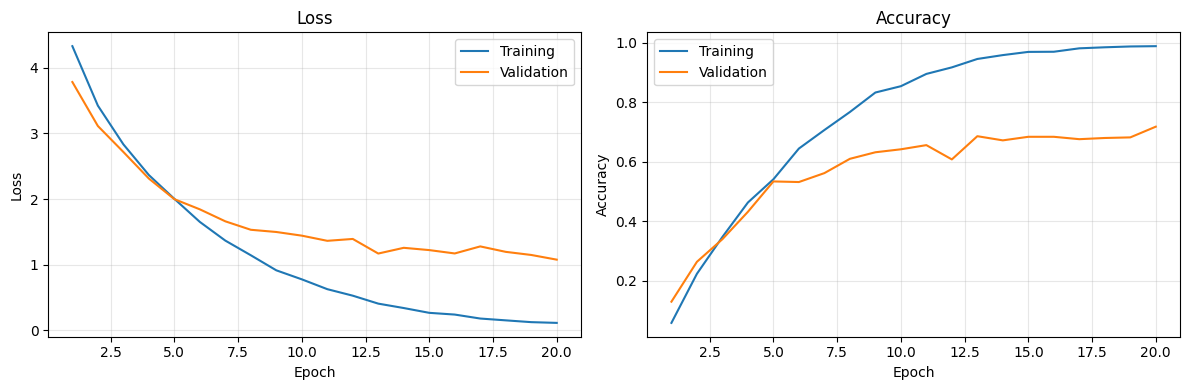

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.epoch, history.train_loss, label='Training')
axes[0].plot(history.epoch, history.val_loss, label='Validation')
axes[0].set(xlabel='Epoch', ylabel='Loss', title='Loss')
axes[1].plot(history.epoch, history.train_accuracy, label='Training')
axes[1].plot(history.epoch, history.val_accuracy, label='Validation')
axes[1].set(xlabel='Epoch', ylabel='Accuracy', title='Accuracy')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
fig.tight_layout()